# Sweep de escala de ruído — Cenário C (treino só-jitter 5 clones / calibração real)

Este notebook foca em **um único cenário** — o que teve melhor desempenho
no experimento anterior: **treino 100% sintético (5 clones jitterados no
clima), calibração com dados reais**. Aqui variamos apenas a **escala do
ruído** (`escala_ruido_x`), começando em `0.10` e aumentando, para ver como
`mae_holdout`, `margem` e `cobertura_holdout` evoluem em função da
intensidade do ruído.

O objetivo é encontrar visualmente o ponto de "melhor ruído": pouco ruído
demais pode não regularizar o suficiente; ruído demais tende a degradar o
sinal real e piorar o MAE.

Como antes: **holdout sempre real**, e a mesma seed é usada em todas as
escalas de ruído testadas, para manter os splits comparáveis entre pontos
do sweep.


In [10]:
from __future__ import annotations

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, VotingRegressor

warnings.filterwarnings("ignore")

np.random.seed(42)


In [11]:
BASE_DIR = Path(os.getcwd())
OUTPUT_DIR = BASE_DIR / "resultados_sweep_escala_ruido"
OUTPUT_DIR.mkdir(exist_ok=True)

CONFIG = {
    "area1": {
        "csv_path": "dataatea1clima.csv",
        "onehot_cols": [
            "Mês", "Dia_semana", "Dia_mês", "prato_principal_1",
            "prato_principal_2", "guarnição", "sobremesa_1", "refeicao",
        ],
        "remove_cafe_da_manha": True,
        "dropna": True,
        "remove_total_zero": True,
    },
    "area2": {
        "csv_path": "dataarea2clima.csv",
        "onehot_cols": [
            "Mês", "Dia_semana", "Dia_mês", "prato_principal_1",
            "prato_principal_2", "guarnição", "sobremesa_1",
        ],
        "remove_cafe_da_manha": False,
        "dropna": False,
        "remove_total_zero": False,
    },
}

CLIMATE_COLS = [
    "Precipitacao_mm", "Temp_max_C", "Temp_min_C",
    "Umid_rel_ar", "Vento_velocidade_ms", "Vento_rajada_maxima_ms",
]

COLUNAS_FILTRO_RARO = ["guarnição", "prato_principal_1", "prato_principal_2", "sobremesa_1"]


## Carregamento dos dados

Mesmo pré-processamento dos notebooks anteriores.

In [12]:
def _resolver_caminho(nomes_possiveis, bases):
    for base in bases:
        for nome in nomes_possiveis:
            candidato = base / nome
            if candidato.exists():
                return candidato
    return None


def _bases_padrao():
    return [BASE_DIR, BASE_DIR / "data", BASE_DIR.parent, BASE_DIR.parent / "data"]


def carregar_dados(area: str):
    """Reproduz o pré-processamento de Previsao_areaX.ipynb."""
    cfg = CONFIG[area]
    nomes = [Path(cfg["csv_path"]).name, f"data{area}.csv", f"data_{area}.csv"]
    caminho = _resolver_caminho(nomes, _bases_padrao())
    if caminho is None:
        raise FileNotFoundError(
            f"Não encontrei o CSV da {area}. Coloque este notebook na mesma pasta "
            f"dos notebooks anteriores (ou ajuste CONFIG['{area}']['csv_path'])."
        )
    data = pd.read_csv(caminho, header=0)

    if cfg["remove_cafe_da_manha"]:
        data = data[data["refeicao"] != "cafe da manha"].copy()
    if cfg["dropna"]:
        data = data.dropna()
    if cfg["remove_total_zero"]:
        data = data[data["total"] != 0]

    for col in COLUNAS_FILTRO_RARO:
        data = data.groupby(col).filter(lambda x: len(x) >= 5)

    data_raw_base = data.reset_index(drop=True).copy()
    data_onehot = pd.get_dummies(data_raw_base, columns=cfg["onehot_cols"])

    atributos = data_onehot.drop(columns=["total"]).columns
    X = data_onehot[atributos]
    y = data_onehot["total"]
    return data_raw_base, X, y


## Jittering climático (só X, igual ao experimento original)

Ruído gaussiano nas colunas contínuas de clima, desvio-padrão calculado por
mês. Aqui `y` nunca é tocado — este notebook foca só no eixo que
efetivamente ajudou no experimento anterior.

In [13]:
def jitter_climatico(X_base, y_base, meta_base, n_copias=2, escala_ruido=0.15, seed=42):
    """
    Gera `n_copias` cópias sintéticas de X_base/y_base com ruído gaussiano nas
    colunas climáticas contínuas. O desvio-padrão do ruído é calculado
    POR MÊS (usando meta_base['Mês']), para respeitar a sazonalidade.
    """
    rng = np.random.default_rng(seed)
    meses = meta_base["Mês"]

    std_por_mes = {}
    for col in CLIMATE_COLS:
        if col not in X_base.columns:
            continue
        std_local = X_base[col].groupby(meses).transform("std")
        std_global = X_base[col].std()
        std_por_mes[col] = std_local.fillna(std_global)

    if not std_por_mes:
        raise ValueError(
            "Nenhuma coluna climática foi encontrada em X_base. "
            "Verifique se o CONFIG aponta para os CSVs com clima."
        )

    copias_X, copias_y = [], []
    for _ in range(n_copias):
        X_sint = X_base.copy()
        for col, sigma_series in std_por_mes.items():
            sigma = sigma_series.to_numpy()
            ruido = rng.normal(loc=0.0, scale=np.clip(sigma, 1e-6, None) * escala_ruido)
            X_sint[col] = X_sint[col].to_numpy() + ruido

        if "Precipitacao_mm" in X_sint.columns:
            X_sint["Precipitacao_mm"] = X_sint["Precipitacao_mm"].clip(lower=0)
        if "Umid_rel_ar" in X_sint.columns:
            X_sint["Umid_rel_ar"] = X_sint["Umid_rel_ar"].clip(0, 100)
        if {"Temp_min_C", "Temp_max_C"}.issubset(X_sint.columns):
            inconsistente = X_sint["Temp_min_C"] > X_sint["Temp_max_C"]
            if inconsistente.any():
                tmp = X_sint.loc[inconsistente, "Temp_min_C"].copy()
                X_sint.loc[inconsistente, "Temp_min_C"] = X_sint.loc[inconsistente, "Temp_max_C"]
                X_sint.loc[inconsistente, "Temp_max_C"] = tmp

        copias_X.append(X_sint)
        copias_y.append(y_base.copy())

    X_jitter = pd.concat(copias_X, ignore_index=True)
    y_jitter = pd.concat(copias_y, ignore_index=True)
    return X_jitter, y_jitter


## Loop de experimento fixo no cenário C

Treino = **só** `n_copias` clones jitterados (sem os dados reais).
Calibração = **dados reais**. O único parâmetro que varia entre chamadas é
`escala_ruido`.

In [14]:
def rodar_sweep_ponto(
    X, y, data_raw_base, escala_ruido, n_copias=5,
    n_repeticoes=15, alpha=0.05,
    test_size=0.3, holdout_size=0.15, verbose=True,
):
    resultados = []
    for seed in range(n_repeticoes):
        # Holdout sempre real.
        X_resto, X_holdout, y_resto, y_holdout = train_test_split(
            X, y, test_size=holdout_size, random_state=seed
        )
        # Split treino/calibração, ainda 100% real nesse ponto.
        X_train_base, X_calib, y_train_base, y_calib = train_test_split(
            X_resto, y_resto, test_size=test_size, random_state=seed
        )
        meta_train_base = data_raw_base.loc[X_train_base.index]

        # Treino = SÓ jitter (n_copias clones, sem os dados reais).
        X_train_final, y_train_final = jitter_climatico(
            X_train_base, y_train_base, meta_train_base,
            n_copias=n_copias, escala_ruido=escala_ruido, seed=seed,
        )

        modelo = VotingRegressor(
            estimators=[
                ("gb", GradientBoostingRegressor(n_estimators=200, random_state=seed)),
                ("rf", RandomForestRegressor(n_estimators=200, random_state=seed, n_jobs=-1)),
            ],
            weights=[3, 1],
        )
        modelo.fit(X_train_final, y_train_final)

        # Calibração = real, sem jitter.
        residuos_calib = np.abs(y_calib.to_numpy() - modelo.predict(X_calib))
        margem = float(np.quantile(residuos_calib, 1 - alpha, method="higher"))

        # MAE e cobertura medidos sempre no holdout real.
        residuos_holdout = np.abs(y_holdout.to_numpy() - modelo.predict(X_holdout))
        mae_holdout = float(residuos_holdout.mean())
        cobertura = float((residuos_holdout <= margem).mean())

        resultados.append({
            "escala_ruido": escala_ruido,
            "seed": seed,
            "n_treino_final": len(X_train_final),
            "n_calib": len(X_calib),
            "mae_holdout": mae_holdout,
            "margem": margem,
            "cobertura_holdout": cobertura,
        })

        if verbose:
            print(
                f"  escala={escala_ruido:.2f}  seed={seed:2d}  "
                f"MAE_holdout={mae_holdout:7.2f}  margem={margem:7.2f}  "
                f"cobertura_holdout={cobertura:.3f}",
                flush=True,
            )

    return pd.DataFrame(resultados)


## Configuração do sweep

`ESCALAS_RUIDO` começa em `0.10` e sobe — ajuste a lista livremente
(intervalo, quantos pontos, até onde ir). O ponto `0.10` é o mesmo tipo de
ruído testado no experimento anterior, só que lá a escala usada no cenário
C era `0.20`; aqui cobrimos uma faixa mais ampla ao redor disso.

In [15]:
AREA = "area1"           # 'area1' ou 'area2'
N_REPETICOES = 15        # reduza para ~5 num teste rápido
N_COPIAS = 5              # mesma quantidade de clones do cenário C (melhor resultado anterior)

ESCALAS_RUIDO = [round(x, 2) for x in np.arange(0.10, 0.85, 0.05)]
# ESCALAS_RUIDO = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

cfg = CONFIG[AREA]
data_raw_base, X, y = carregar_dados(AREA)

print(f"Área: {AREA}")
print(f"Observações: {len(X)}  |  Atributos: {X.shape[1]}")
print(f"Escalas de ruído a testar: {ESCALAS_RUIDO}")


Área: area1
Observações: 1363  |  Atributos: 200
Escalas de ruído a testar: [np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.25), np.float64(0.3), np.float64(0.35), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.55), np.float64(0.6), np.float64(0.65), np.float64(0.7), np.float64(0.75), np.float64(0.8)]


## Rodando o sweep

Mesmas seeds (0..N_REPETICOES-1) em todas as escalas, para manter os splits comparáveis entre pontos.

In [16]:
resultados_sweep = []

for escala in ESCALAS_RUIDO:
    print(f"\n=== escala_ruido = {escala:.2f} ===")
    df_ponto = rodar_sweep_ponto(
        X, y, data_raw_base,
        escala_ruido=escala, n_copias=N_COPIAS,
        n_repeticoes=N_REPETICOES,
    )
    resultados_sweep.append(df_ponto)

resultados_sweep = pd.concat(resultados_sweep, ignore_index=True)
resultados_sweep["area"] = AREA
resultados_sweep.to_csv(OUTPUT_DIR / f"sweep_escala_ruido_{AREA}.csv", index=False)
print(f"\nSalvo: {OUTPUT_DIR / f'sweep_escala_ruido_{AREA}.csv'}")



=== escala_ruido = 0.10 ===
  escala=0.10  seed= 0  MAE_holdout= 125.97  margem= 360.47  cobertura_holdout=0.956
  escala=0.10  seed= 1  MAE_holdout= 119.94  margem= 301.74  cobertura_holdout=0.961
  escala=0.10  seed= 2  MAE_holdout= 129.13  margem= 321.24  cobertura_holdout=0.932
  escala=0.10  seed= 3  MAE_holdout= 129.20  margem= 397.01  cobertura_holdout=0.961
  escala=0.10  seed= 4  MAE_holdout= 133.27  margem= 326.89  cobertura_holdout=0.941
  escala=0.10  seed= 5  MAE_holdout= 120.51  margem= 318.32  cobertura_holdout=0.941
  escala=0.10  seed= 6  MAE_holdout= 130.12  margem= 371.34  cobertura_holdout=0.956
  escala=0.10  seed= 7  MAE_holdout= 132.77  margem= 361.59  cobertura_holdout=0.941
  escala=0.10  seed= 8  MAE_holdout= 122.10  margem= 349.64  cobertura_holdout=0.951
  escala=0.10  seed= 9  MAE_holdout= 138.54  margem= 377.15  cobertura_holdout=0.932
  escala=0.10  seed=10  MAE_holdout= 108.81  margem= 334.55  cobertura_holdout=0.976
  escala=0.10  seed=11  MAE_holdout=

## Resumo por escala de ruído

Média e desvio-padrão de cada métrica, por escala de ruído testada.

In [17]:
resumo_sweep = (
    resultados_sweep
    .groupby("escala_ruido")
    .agg(
        mae_medio=("mae_holdout", "mean"),
        mae_std=("mae_holdout", "std"),
        margem_media=("margem", "mean"),
        margem_std=("margem", "std"),
        cobertura_media=("cobertura_holdout", "mean"),
        cobertura_std=("cobertura_holdout", "std"),
    )
    .round(4)
)
resumo_sweep


,mae_medio,mae_std,margem_media,margem_std,cobertura_media,cobertura_std
escala_ruido,,,,,,
0.10,126.9558,8.5175,341.1364,27.9404,0.9473,0.0129
0.15,125.5652,9.0436,336.9297,32.1478,0.9473,0.0142
0.20,125.6943,8.6323,338.2193,29.0111,0.9467,0.0120
0.25,125.3374,9.0315,337.4894,27.1376,0.9486,0.0138
0.30,124.6649,8.8675,337.8382,30.8504,0.9489,0.0101
0.35,125.1819,9.1170,341.2053,31.0642,0.9502,0.0131
0.40,124.7292,9.1021,339.2954,27.8084,0.9522,0.0125
0.45,124.5284,8.7775,337.4850,30.5070,0.9486,0.0133
0.50,124.6208,9.3097,337.7209,31.1046,0.9473,0.0112


## Gráfico: MAE, margem e cobertura em função da escala de ruído

Linha = média entre as `N_REPETICOES` seeds; faixa sombreada = ±1
desvio-padrão. A linha pontilhada no gráfico de cobertura marca a meta de
95%.

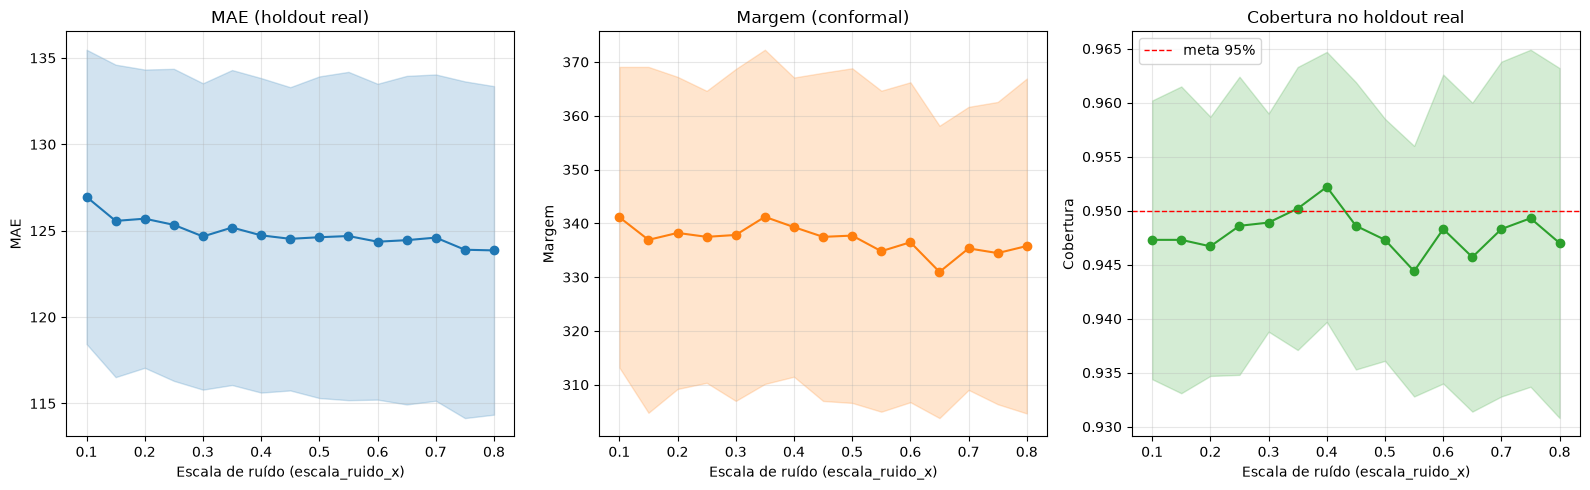

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

escalas = resumo_sweep.index.to_numpy()

# --- MAE ---
ax = axes[0]
media, std = resumo_sweep["mae_medio"].to_numpy(), resumo_sweep["mae_std"].to_numpy()
ax.plot(escalas, media, marker="o", color="tab:blue")
ax.fill_between(escalas, media - std, media + std, alpha=0.2, color="tab:blue")
ax.set_title("MAE (holdout real)")
ax.set_xlabel("Escala de ruído (escala_ruido_x)")
ax.set_ylabel("MAE")
ax.grid(True, alpha=0.3)

# --- Margem ---
ax = axes[1]
media, std = resumo_sweep["margem_media"].to_numpy(), resumo_sweep["margem_std"].to_numpy()
ax.plot(escalas, media, marker="o", color="tab:orange")
ax.fill_between(escalas, media - std, media + std, alpha=0.2, color="tab:orange")
ax.set_title("Margem (conformal)")
ax.set_xlabel("Escala de ruído (escala_ruido_x)")
ax.set_ylabel("Margem")
ax.grid(True, alpha=0.3)

# --- Cobertura ---
ax = axes[2]
media, std = resumo_sweep["cobertura_media"].to_numpy(), resumo_sweep["cobertura_std"].to_numpy()
ax.plot(escalas, media, marker="o", color="tab:green")
ax.fill_between(escalas, media - std, media + std, alpha=0.2, color="tab:green")
ax.axhline(0.95, color="red", linestyle="--", linewidth=1, label="meta 95%")
ax.set_title("Cobertura no holdout real")
ax.set_xlabel("Escala de ruído (escala_ruido_x)")
ax.set_ylabel("Cobertura")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"sweep_escala_ruido_{AREA}.png", dpi=150, bbox_inches="tight")
plt.show()
